# Topic 21 Assignment - The Director's Dashboard - Instructor Solutions

## Scenario

You are still the Ghanaian retail distributor's analyst from Topic 20. The managing director read your 2023 Trading Review and had one response: "I cannot bring a DataFrame into a board meeting. Give me a page of charts."

Your job this time is not to find new numbers - every number you need, you already found in Topic 20. Your job is to turn five of those findings into five charts, each one built to the standard this topic set: a title that states the finding, axes labelled with units, a legend when there is more than one series, and the right chart type for the question, not the first one you thought of.

### What you are practising

| Skill | Where |
|---|---|
| Choosing a chart type from the question, not habit | Part 1 |
| Bar charts with emphasis, sorted, labelled | Part 3 |
| Line charts with a rolling average | Part 4 |
| Box plots and reading a distribution | Part 5 |
| A sequential heatmap for a count grid | Part 6 |
| Composition charts, used only when justified | Part 7 |
| Assembling a multi-panel dashboard | Part 8 |
| Checking a chart's structure in code, not just by eye | Every check cell |
| Submitting work with Git and GitHub | Part 11 |

## What you must submit

A **public** GitHub repository named **`itfy-data-visualization`** containing:

1. this notebook, completed, **run from top to bottom so every output is visible**;
2. `data/` - the six source CSVs, unchanged;
3. `charts/` - at least six saved PNGs: one bar, one line, one distribution, one relationship or heatmap, one composition chart, and the final dashboard;
4. `charts/captions.json` - one entry per saved chart, with its chart type and the finding it shows;
5. `README.md` - your findings, written for the managing director, with the dashboard image embedded.

Full submission instructions, written for Windows with no assumed knowledge, are in [the GitHub submission guide](../../data_analysis_process/topic19d_appendix_submitting_with_github.ipynb). You have now done this twice.

### Rules

- **Complete every function skeleton.** Loose code in a cell instead of a completed function loses that part's marks.
- **Every chart needs a title that states a finding, axis labels with units, and a legend if it has more than one series.** The check cells test this in code - they will tell you if a chart is missing one.
- **At most one composition chart (pie or waffle), and only for five categories or fewer that genuinely sum to a whole.** Justify your choice of pie, waffle, or bar in the one line Part 7 asks for.
- **Never a dual-axis chart.** If two measures do not share a scale, that is two charts.
- **One series, one colour**, unless colour is telling series apart or marking the one bar or line that is the finding.
- **Never modify the files in `data/`.**

## How to work through this notebook

Replace every `# TODO n` with your code, and delete each `raise NotImplementedError(...)` once the function works. The check cell beneath each part tells you whether your answer is right - it compares against figures and chart properties that are known to be correct, so a `False` means your code, not the check, is wrong.

Work in order. Every part uses the `analysis` table built in Part 2.

---

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"


def find_data_dir():
    candidates = [Path.cwd() / "data", Path.cwd() / "data_visualization" / "data",
                  Path.cwd().parent.parent / "data_visualization" / "data"]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find orders.csv. Looked in: " +
                             ", ".join(str(c) for c in candidates))


DATA_DIR = find_data_dir()
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
print("data folder:", DATA_DIR)

data folder: /home/johnny/Projects/itfy-da/data_visualization/data


## Part 1 - Chart-selection memo

Before building anything, decide the chart type for each of the director's five questions, and say why in one line each, using the chart-selection rule from the main lesson.

1. Which segment is the most profitable?
2. Did order volume grow steadily through 2023, or in bursts?
3. Which category has the widest spread of unit prices?
4. Which day-and-channel combination is busiest?
5. How concentrated is profit among the best customers?

**Chart-selection memo (solution):**

1. Bar, sorted, one colour with emphasis - comparing a measure across a small set of categories.
2. Line, with a rolling average - a trend over 12 consecutive months.
3. Box plot - the question is about spread and shape, not a single number per category.
4. Heatmap, sequential - two categorical dimensions at once; a grid of colour beats a grid of numbers.
5. Composition (bar or pie, justified) - the question is explicitly "what share of the whole."

---
## Part 2 - Rebuild the analysis table

Paste the function you built in Topic 20. This is the same contract: five raw tables in, one analysis-ready table out.

In [2]:
def clean_region(series):
    return (series.str.strip().str.replace(r"\s+", " ", regex=True).str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)
    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")
    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))
    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)
    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)
    if len(table) != expected_rows:
        raise ValueError("Row count changed during wrangling.")
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)

In [3]:
# Check cell. All five must print True.
print("rows:            ", len(analysis) == 1200)
print("orphans:         ", analysis["region"].isna().sum() == 27)
print("returned:        ", analysis["was_returned"].sum() == 96)
print("total revenue:   ", round(analysis["revenue_ghs"].sum(), 2) == 230001.08)
print("total profit:    ", round(analysis["profit_ghs"].sum(), 2) == 65886.38)

rows:             True
orphans:          True
returned:         True
total revenue:    True
total profit:     True


---
## Part 3 - Bar chart: profit by segment

Write `plot_profit_by_segment(analysis)`, returning `(fig, ax)`. It must:

- show total profit by segment, sorted highest to lowest;
- colour the top segment's bar in `PALETTE["blue"]` and every other bar in `MUTED`;
- add a value label on each bar;
- set a title that states which segment is most profitable and by how much;
- label both axes, with units on the y-axis.

In [4]:
def plot_profit_by_segment(analysis):
    """Bar chart of total profit by segment, sorted, with the leader emphasised."""
    profit = analysis.groupby("segment")["profit_ghs"].sum().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    colors = [PALETTE["blue"] if seg == profit.index[0] else MUTED for seg in profit.index]
    bars = ax.bar(profit.index, profit.values, color=colors)
    ax.bar_label(bars, fmt="GHS %.0f", padding=3)
    ax.set_title(f"{profit.index[0]} is the most profitable segment, at GHS {profit.values[0]:,.0f}")
    ax.set_xlabel("Segment")
    ax.set_ylabel("Profit (GHS)")
    return fig, ax

3 bars:           True
sorted desc:      True
values correct:   True
top bar is blue:  True
title present:    True
ylabel has units: True


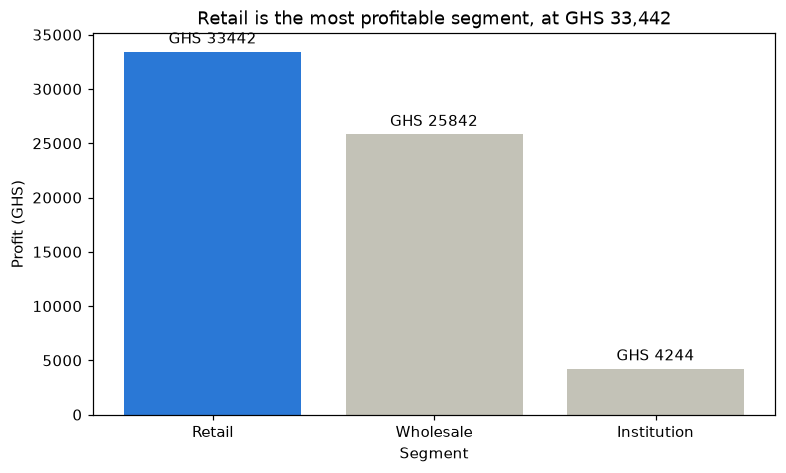

In [5]:
# Check cell. All must print True.
fig3, ax3 = plot_profit_by_segment(analysis)
heights = [p.get_height() for p in ax3.patches]
print("3 bars:          ", len(ax3.patches) == 3)
print("sorted desc:     ", heights == sorted(heights, reverse=True))
print("values correct:  ", [round(h, 2) for h in heights] == [33442.04, 25842.35, 4244.12])
print("top bar is blue: ", matplotlib.colors.to_hex(ax3.patches[0].get_facecolor()) == PALETTE["blue"])
print("title present:   ", len(ax3.get_title()) > 10)
print("ylabel has units:", "GHS" in ax3.get_ylabel())
plt.show()

---
## Part 4 - Line chart: order volume over time

Write `plot_monthly_order_count(analysis)`, returning `(fig, ax)`. It must:

- plot the **number of orders per month** (not revenue) for 2023, in `MUTED`, with markers;
- overlay a 3-month rolling average in `PALETTE["blue"]`;
- include a legend naming both lines;
- set a title - check carefully whether one month or two months share the peak before you word it.

In [6]:
def plot_monthly_order_count(analysis):
    """Line chart of monthly order count, with a 3-month rolling average."""
    monthly = analysis.groupby(analysis["order_date"].dt.to_period("M")).size()
    monthly.index = monthly.index.astype(str)
    rolling = monthly.rolling(3).mean()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(monthly.index, monthly.values, color=MUTED, marker="o", markersize=4,
            linewidth=1.5, label="Monthly orders")
    ax.plot(monthly.index, rolling.values, color=PALETTE["blue"], linewidth=2.5,
            label="3-month average")
    ax.set_title("Order volume peaked in August and November 2023 (115 orders each)")
    ax.set_xlabel("Month of 2023")
    ax.set_ylabel("Number of orders")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False)
    return fig, ax

2 lines:          True
legend present:   True
title present:    True


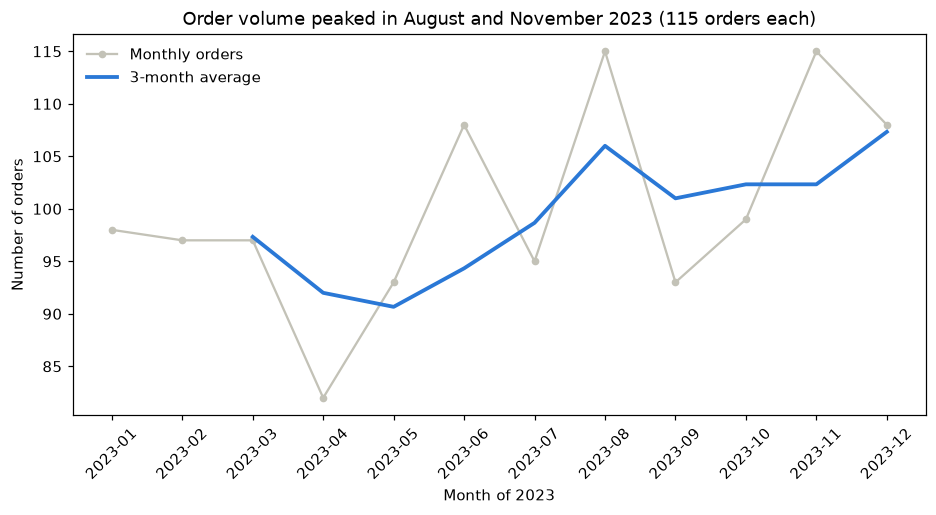

In [7]:
# Check cell. All must print True.
fig4, ax4 = plot_monthly_order_count(analysis)
print("2 lines:         ", len(ax4.lines) == 2)
print("legend present:  ", ax4.get_legend() is not None)
print("title present:   ", len(ax4.get_title()) > 10)
plt.show()

---
## Part 5 - Box plot: unit price by category

Write `plot_unit_price_distribution(analysis)`, returning `(fig, ax)`. It must:

- show a box plot of `unit_price_ghs` for every category, ordered by median (highest first);
- use `patch_artist=True` so the boxes can be coloured `PALETTE["blue"]`;
- set a title naming the category with the highest median.

In [8]:
def plot_unit_price_distribution(analysis):
    """Box plot of unit price by category, sorted by median, highest first."""
    order = (analysis.groupby("category")["unit_price_ghs"].median()
             .sort_values(ascending=False).index.tolist())
    data = [analysis.loc[analysis["category"] == c, "unit_price_ghs"].dropna() for c in order]
    fig, ax = plt.subplots(figsize=(10, 5))
    bp = ax.boxplot(data, tick_labels=order, patch_artist=True,
                     flierprops={"markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"})
    for patch in bp["boxes"]:
        patch.set_facecolor(PALETTE["blue"])
        patch.set_alpha(0.8)
    ax.set_title("Cooking Oils has the highest median unit price of any category")
    ax.set_xlabel("Category")
    ax.set_ylabel("Unit price (GHS)")
    ax.tick_params(axis="x", rotation=25)
    return fig, ax

7 box patches:    True
title present:    True


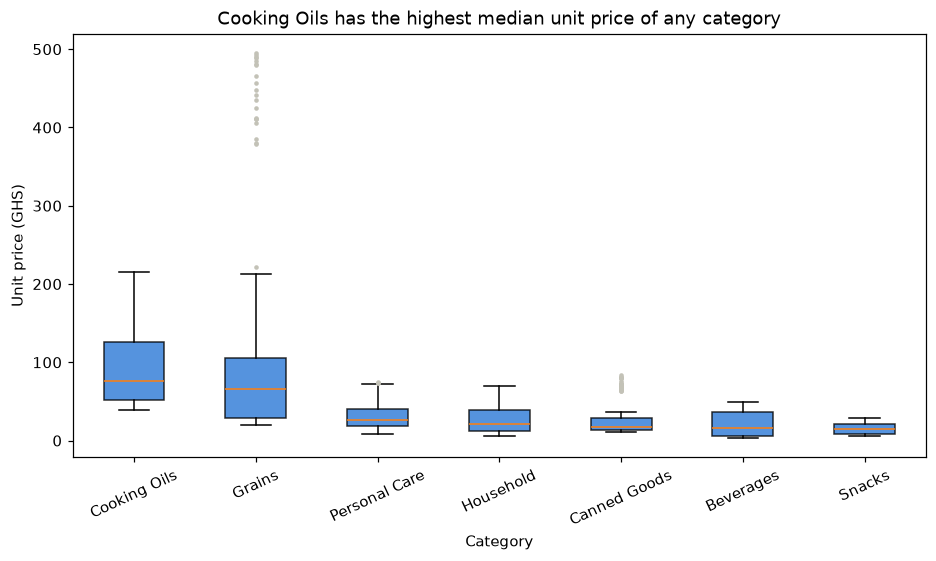

In [9]:
# Check cell. All must print True.
fig5, ax5 = plot_unit_price_distribution(analysis)
print("7 box patches:   ", len(ax5.patches) == 7)
print("title present:   ", len(ax5.get_title()) > 10)
plt.show()

---
## Part 6 - Heatmap: busiest day and channel

Write `plot_order_heatmap(analysis)`, returning `(fig, ax, grid)` where `grid` is the weekday-by-channel order-count DataFrame. It must:

- use `ax.imshow` with a **sequential** colormap (`"Blues"`) - this is a count, not a correlation, so it does not get the diverging treatment;
- order weekdays Monday to Sunday, and channels in a fixed order;
- annotate each cell with its count;
- set a title naming the single busiest day-and-channel combination.

In [10]:
def plot_order_heatmap(analysis):
    """Sequential heatmap of order count by weekday and channel."""
    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    channel_order = ["Field Agent", "Online", "Phone", "Shop"]
    grid = (analysis.groupby(["weekday", "channel"]).size()
            .unstack().reindex(weekday_order)[channel_order])
    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(grid.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(channel_order)))
    ax.set_xticklabels(channel_order)
    ax.set_yticks(range(len(weekday_order)))
    ax.set_yticklabels(weekday_order)
    for i in range(len(weekday_order)):
        for j in range(len(channel_order)):
            ax.text(j, i, int(grid.values[i, j]), ha="center", va="center", fontsize=8)
    ax.set_title("Shop on Thursday is the single busiest day-and-channel combination")
    fig.colorbar(im, ax=ax, shrink=0.85, label="Number of orders")
    return fig, ax, grid

one image:        True
shape 7x4:        True
busiest is Shop/Thursday, 90: True


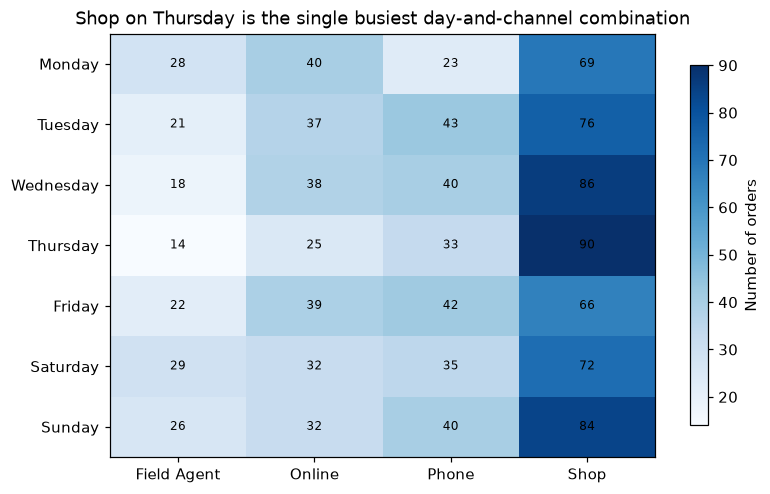

In [11]:
# Check cell. All must print True.
fig6, ax6, grid6 = plot_order_heatmap(analysis)
print("one image:       ", len(ax6.get_images()) == 1)
print("shape 7x4:       ", grid6.shape == (7, 4))
busiest = grid6.stack().idxmax()
print("busiest is Shop/Thursday, 90:", busiest == ("Thursday", "Shop") and grid6.stack().max() == 90)
plt.show()

---
## Part 7 - Composition: customer tiers

Write `plot_customer_tier_composition(analysis)`, returning `(fig, ax, tier_share, composition_justification)`. It must:

- split customers into `Bronze`, `Silver`, `Gold` tiers by total profit with `pd.qcut(..., 3, ...)`, exactly as Topic 20 did;
- compute each tier's share of total profit as `tier_share` (a Series indexed Bronze, Silver, Gold);
- build **either** a bar or a pie chart of `tier_share` - your choice;
- set `composition_justification` to a one-line string explaining why you chose that chart type over the other, using the rule from 21f.

In [12]:
def plot_customer_tier_composition(analysis):
    """Composition chart of profit share by customer tier (Bronze/Silver/Gold)."""
    cust_profit = analysis.groupby("customer_id")["profit_ghs"].sum()
    tiers = pd.qcut(cust_profit, 3, labels=["Bronze", "Silver", "Gold"])
    tier_share = (cust_profit.groupby(tiers, observed=True).sum()
                  .pipe(lambda s: (s / s.sum() * 100).round(1))
                  .reindex(["Bronze", "Silver", "Gold"]))

    composition_justification = (
        "A bar chart: 3 categories is within the pie-chart limit, but Gold vs Silver "
        "(69.2% vs 22.3%) is still easier to compare as bar length than as slice angle."
    )
    fig, ax = plt.subplots(figsize=(7, 4.5))
    colors = [PALETTE["blue"] if t == "Gold" else MUTED for t in tier_share.index]
    bars = ax.bar(tier_share.index, tier_share.values, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_title("Gold-tier customers hold 69.2% of all profit")
    ax.set_xlabel("Customer tier")
    ax.set_ylabel("Share of total profit (%)")
    return fig, ax, tier_share, composition_justification

3 tiers:          True
shares correct:   True
justified:        True


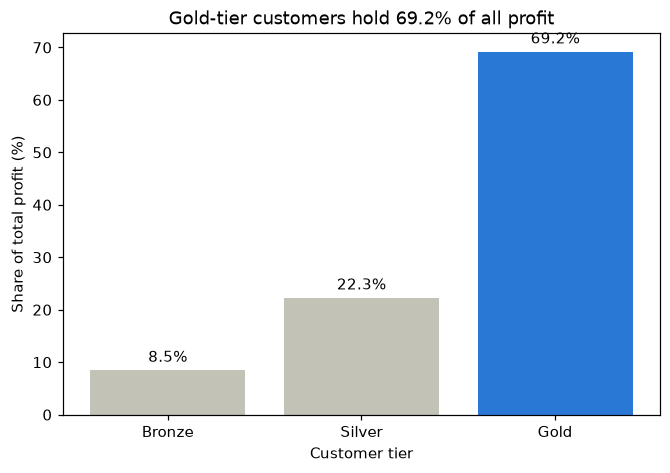

In [13]:
# Check cell. All must print True.
fig7, ax7, tier_share7, justification7 = plot_customer_tier_composition(analysis)
print("3 tiers:         ", len(tier_share7) == 3)
print("shares correct:  ", tier_share7.to_dict() == {"Bronze": 8.5, "Silver": 22.3, "Gold": 69.2})
print("justified:       ", len(justification7) > 20)
plt.show()

---
## Part 8 - The dashboard

Write `build_dashboard(analysis, charts_dir)`, which builds one Figure with `plt.subplots(2, 3)` containing all five charts above (one panel may hold a title/summary instead of a sixth chart), saves it to `charts_dir / "director_dashboard.png"` at 150 dpi, and returns the saved path.

In [14]:
def build_dashboard(analysis, charts_dir):
    """Assemble Parts 3-7 into one 2x3 dashboard figure, saved to disk."""
    charts_dir.mkdir(exist_ok=True)
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    profit = analysis.groupby("segment")["profit_ghs"].sum().sort_values(ascending=False)
    colors = [PALETTE["blue"] if s == profit.index[0] else MUTED for s in profit.index]
    axes[0, 0].bar(profit.index, profit.values, color=colors)
    axes[0, 0].set_title("Retail is the most profitable segment")
    axes[0, 0].set_ylabel("Profit (GHS)")

    monthly = analysis.groupby(analysis["order_date"].dt.to_period("M")).size()
    monthly.index = monthly.index.astype(str)
    axes[0, 1].plot(monthly.index, monthly.values, color=PALETTE["blue"], marker="o")
    axes[0, 1].set_title("Orders peaked in Aug and Nov")
    axes[0, 1].set_ylabel("Number of orders")
    axes[0, 1].tick_params(axis="x", rotation=45, labelsize=7)

    order = (analysis.groupby("category")["unit_price_ghs"].median()
             .sort_values(ascending=False).index.tolist())
    data = [analysis.loc[analysis["category"] == c, "unit_price_ghs"].dropna() for c in order]
    axes[0, 2].boxplot(data, tick_labels=order)
    axes[0, 2].set_title("Cooking Oils: widest, highest unit price")
    axes[0, 2].set_ylabel("Unit price (GHS)")
    axes[0, 2].tick_params(axis="x", rotation=60, labelsize=6)

    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    channel_order = ["Field Agent", "Online", "Phone", "Shop"]
    grid = (analysis.groupby(["weekday", "channel"]).size()
            .unstack().reindex(weekday_order)[channel_order])
    im = axes[1, 0].imshow(grid.values, cmap="Blues", aspect="auto")
    axes[1, 0].set_xticks(range(len(channel_order)))
    axes[1, 0].set_xticklabels(channel_order, rotation=30, ha="right", fontsize=7)
    axes[1, 0].set_yticks(range(len(weekday_order)))
    axes[1, 0].set_yticklabels(weekday_order, fontsize=7)
    axes[1, 0].set_title("Shop + Thursday is busiest")
    fig.colorbar(im, ax=axes[1, 0], shrink=0.85, label="Orders")

    cust_profit = analysis.groupby("customer_id")["profit_ghs"].sum()
    tiers = pd.qcut(cust_profit, 3, labels=["Bronze", "Silver", "Gold"])
    tier_share = (cust_profit.groupby(tiers, observed=True).sum()
                  .pipe(lambda s: s / s.sum() * 100).reindex(["Bronze", "Silver", "Gold"]))
    axes[1, 1].bar(tier_share.index, tier_share.values, color=PALETTE["blue"])
    axes[1, 1].set_title("Gold holds 69.2% of profit")
    axes[1, 1].set_ylabel("Share of total profit (%)")

    axes[1, 2].axis("off")
    axes[1, 2].text(0.5, 0.5, "2023 Trading Review\nBoard summary", ha="center", va="center", fontsize=13)

    fig.suptitle("2023 Trading Review - board summary", fontsize=15)
    fig.tight_layout()
    out_path = charts_dir / "director_dashboard.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    return out_path

dashboard saved:  True


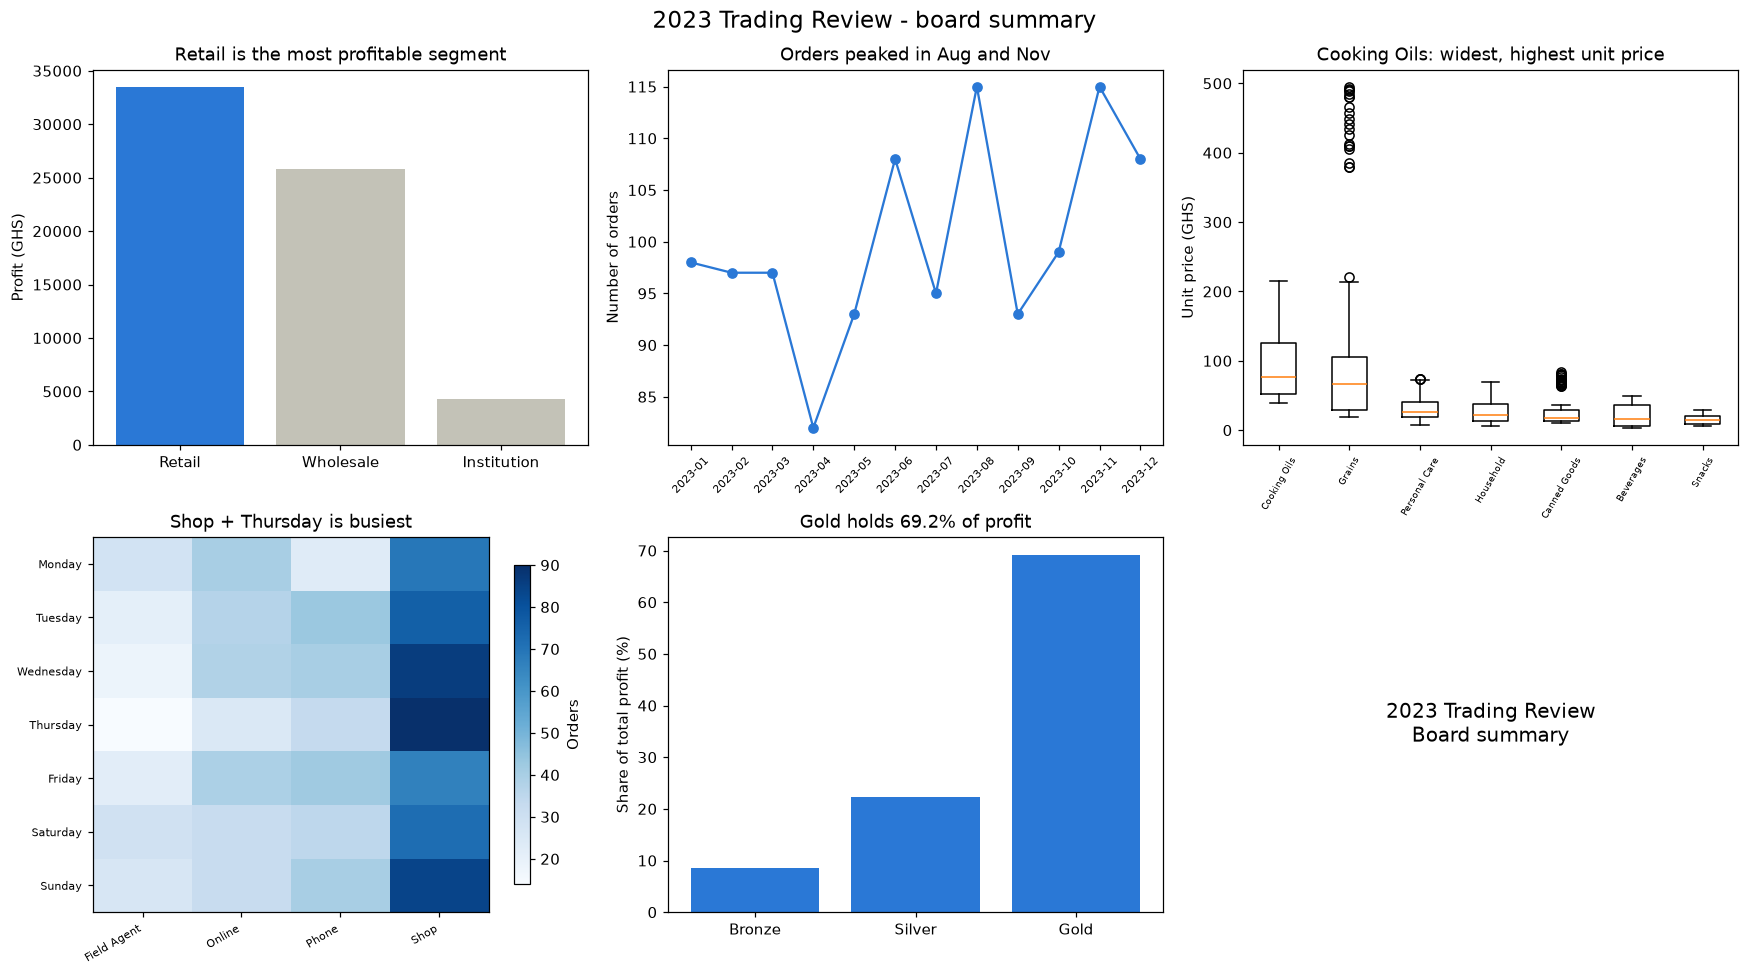

In [15]:
# Check cell. Must print True.
charts_dir = Path("charts")
dashboard_path = build_dashboard(analysis, charts_dir)
print("dashboard saved: ", dashboard_path.exists() and dashboard_path.stat().st_size > 0)
plt.show()

---
## Part 9 - Captions manifest

Write `build_captions(charts_dir)`, which writes `charts_dir / "captions.json"` - a JSON list with one object per PNG in `charts_dir`, each with `"file"`, `"chart_type"`, and `"finding"` keys - and returns the path it wrote to. Save the five individual charts from Parts 3-7 to `charts_dir` first (each with `fig.savefig(...)`), in addition to the dashboard Part 8 already saved.

In [16]:
def build_captions(charts_dir):
    """Write charts/captions.json: one entry per saved PNG, describing its finding."""
    fig3.savefig(charts_dir / "profit_by_segment.png", dpi=150, bbox_inches="tight")
    fig4.savefig(charts_dir / "monthly_order_count.png", dpi=150, bbox_inches="tight")
    fig5.savefig(charts_dir / "unit_price_distribution.png", dpi=150, bbox_inches="tight")
    fig6.savefig(charts_dir / "order_heatmap.png", dpi=150, bbox_inches="tight")
    fig7.savefig(charts_dir / "customer_tier_composition.png", dpi=150, bbox_inches="tight")

    captions = [
        {"file": "profit_by_segment.png", "chart_type": "bar",
         "finding": "Retail is the most profitable segment, at GHS 33,442.04."},
        {"file": "monthly_order_count.png", "chart_type": "line",
         "finding": "Order volume peaked in August and November 2023, at 115 orders each."},
        {"file": "unit_price_distribution.png", "chart_type": "box",
         "finding": "Cooking Oils has the highest median unit price of any category."},
        {"file": "order_heatmap.png", "chart_type": "heatmap",
         "finding": "Shop on Thursday is the single busiest day-and-channel combination."},
        {"file": "customer_tier_composition.png", "chart_type": "bar",
         "finding": "Gold-tier customers hold 69.2% of all profit."},
        {"file": "director_dashboard.png", "chart_type": "dashboard",
         "finding": "The 2023 Trading Review, as five findings on one page."},
    ]
    out_path = charts_dir / "captions.json"
    with open(out_path, "w") as f:
        json.dump(captions, f, indent=2)
    return out_path

In [17]:
# Check cell. All must print True.
captions_path = build_captions(charts_dir)
with open(captions_path) as f:
    captions = json.load(f)
print("captions.json written:", captions_path.exists())
print("6 entries:            ", len(captions) == 6)
print("all keys present:     ", all({"file", "chart_type", "finding"} <= set(c.keys()) for c in captions))

captions.json written: True
6 entries:             True
all keys present:      True


---
### Your findings

**1. Headline for the board:**

*(Model answer - grade for numbers and reasoning, not exact wording.)*

**2. The one chart you expect the most questions about, and why:**

*(Write your answer here.)*

**3. Which composition-chart choice you made in Part 7, and why the other option would have been worse here:**

*(Write your answer here.)*

**4. Two limitations of this dashboard:**

1. *(Write your answer here.)*
2. *(Write your answer here.)*

**5. What chart you would add next, and what question it would answer:**

*(Write your answer here.)*

**Model answers:**

1. **Headline:** Retail drove 2023 profit (GHS 33,442.04 of GHS 65,886.38 total), but order volume - not revenue - was the year's real swing factor, peaking at 115 orders in both August and November.
2. **Most questioned chart:** the heatmap (Part 6) - board members often ask "why Thursday," and the honest answer is this dataset does not say; it shows *where* to look, not *why*.
3. **Composition choice:** a bar chart for the three customer tiers - with only a 46.9-point gap between the smallest and largest share, a pie's slice angles would be harder to compare at a glance than three bar heights.
4. **Limitations:** (a) the dashboard is 2023 only - there is no prior year to compare growth against; (b) "busiest" by order count is not the same as "most profitable" - Part 6's heatmap and Part 3's bar chart answer different questions and should not be read as the same ranking.
5. **Next chart:** a line of profit margin (not just profit) by month, to check whether the Nov-Dec revenue spike from Topic 20 came with the same margin as the rest of the year, or at a discount.

---
## Marking rubric

| Area | What earns the marks | Marks |
|---|---:|---:|
| Chart-selection memo | All five chart types correctly matched to the question, with a real reason each | 10 |
| Analysis table rebuilt | All five checks pass | 8 |
| Bar chart (Part 3) | Sorted, emphasis colour correct, value labels, title states the finding, units on y-axis | 12 |
| Line chart (Part 4) | Correct measure (count, not revenue), rolling average, legend, title accounts for the tie | 12 |
| Box plot (Part 5) | Sorted by median, 7 categories, correctly coloured, title names the leader | 10 |
| Heatmap (Part 6) | Sequential colormap, correct orientation and order, annotated, title names the busiest cell | 12 |
| Composition chart (Part 7) | Correct tier shares, a real justification for bar vs pie, title states the leading tier's share | 12 |
| Dashboard (Part 8) | All five findings present in one figure, saved correctly | 10 |
| Captions manifest (Part 9) | Valid JSON, one entry per chart, each finding stated in words | 8 |
| Findings and limitations | Numbers in every claim; the composition justification is defended, not just repeated | 10 |
| Repository, README, commits | Public repo, correct structure, README written for the director, dashboard embedded | 10 |
| **Total** | | **114** |

Marks are lost for: any chart missing a title, axis units, or a legend where one is needed; a composition chart used for more than five categories or without a stated justification; a dual-axis chart anywhere; `NotImplementedError` left in any function; and a repository that is not public.

## References

### Topic 21 material
- [Main lesson - Topic 21 Data Visualization](../topic21_data_visualization.ipynb)
- [21a - Anatomy of a chart](../topic21a_anatomy_of_a_chart.ipynb)
- [21b - Comparing categories](../topic21b_comparing_categories.ipynb)
- [21c - Change over time](../topic21c_change_over_time.ipynb)
- [21d - Distributions](../topic21d_distributions.ipynb)
- [21e - Relationships](../topic21e_relationships.ipynb)
- [21f - Composition and seaborn](../topic21f_composition_and_seaborn.ipynb)
- [21g - Visualization practice](../topic21g_visualization_practice.ipynb)

### matplotlib and seaborn documentation
- [matplotlib: Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
- [matplotlib: Choosing colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
- [seaborn: An introduction](https://seaborn.pydata.org/tutorial/introduction.html)

### Elsewhere in the course
- [Topic 20 - Data wrangling](../../data_wrangling/topic20_data_wrangling.ipynb)
- [Submitting your work with GitHub](../../data_analysis_process/topic19d_appendix_submitting_with_github.ipynb)